# Projekt - fáza č. 3

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (OneHotEncoder, TargetEncoder, StandardScaler,
                                   PowerTransformer, KBinsDiscretizer)
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, cross_validate, cross_val_predict,
                                     GridSearchCV, validation_curve)
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.utils import resample
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             ConfusionMatrixDisplay, classification_report)
sns.set_theme(style="whitegrid")

## Príprava dát (toto je prevzaté z fázy 2)

Fáza 3 je v samostatnom notebooku, preto tu bez zmeny opakujeme čistenie a predspracovanie z fázy 2, aby bol notebook vykonateľný sám osebe:

* delenie 80/20 podľa jednotiek (`id_unit`), stratifikované na `Failure`, `random_state = 42` - rovnaké delenie ako vo fáze 2,
* čistenie a zlúčenie troch tabuliek (`make_numeric_frame`),
* pipeline z 2.3: one-hot, target encoding depa, orezanie 1,5 x IQR -> medián -> Yeo-Johnson -> StandardScaler a výber 16 atribútov z 2.2.

Všetko, čo sa učí z dát, je v `sklearn` pipeline, takže sa učí iba na trénovacej časti (aj vnútri krížovej validácie).

In [2]:
RANDOM_STATE = 42
TEST_SIZE = 0.20

def parse_dates(col):
    s = pd.Series(col).astype(str).str.strip()
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for fmt in ["%Y-%m-%d", "%Y/%m/%d", "%d %b %Y", "%m/%d/%Y, %H:%M:%S", "%Y-%m-%d %H:%M:%S"]:
        out = out.fillna(pd.to_datetime(s, format=fmt, errors="coerce"))
    return out

def clean_gateways(df):
    df = df.copy().rename(columns={"Lon": "lon", "idDepot": "id_deport", "macAddress": "mac_addr",
                                   "versionFirmware": "version_firmware", "Vendor": "vendor",
                                   "Technician": "technician"})
    if "gateway_id" not in df.columns:
        df = df.reset_index()
    df["gateway_id"] = pd.to_numeric(df["gateway_id"].astype(str).str.replace(r"\D", "", regex=True),
                                     errors="coerce").astype("Int64")
    df["id_unit"] = pd.to_numeric(df["id_unit"], errors="coerce").astype("Int64")
    for c in ["install_date", "seen_last"]:
        df[c] = parse_dates(df[c])
    return df

def clean_readings(df):
    df = df.copy().rename(columns={"currentMotor": "curr_motor", "oilTemperature": "oil_temp",
                                   "pressure_reservoir": "press_reserv", "rmsVibration": "rms_vibration",
                                   "Flowmeter": "flow", "dischargeDewpoint": "dis_dewp", "Failure": "fail"})
    df["id_unit"] = pd.to_numeric(df["id_unit"].astype(str).str.strip().str.replace(r"\D", "", regex=True),
                                  errors="coerce")
    bad = df["id_unit"] > 2000                      # chybne id v tvare 90000 + skutocne id
    df.loc[bad, "id_unit"] = df.loc[bad, "id_unit"] - 90000
    df["id_unit"] = df["id_unit"].astype("Int64")
    df["cycle_ts"] = parse_dates(df["cycle_ts"])
    for col, bad_value in {"oil_temp": -999, "curr_motor": 99, "dp_filter": 120}.items():
        df[col] = df[col].replace(bad_value, np.nan)   # chybove kody senzorov
    sensor_cols = ["curr_motor", "dp_filter", "oil_temp", "press_reserv", "rms_vibration", "flow", "dis_dewp"]
    agg = {c: "mean" for c in sensor_cols}
    agg["fail"] = "max"
    return df.groupby(["id_unit", "cycle_ts"], as_index=False).agg(agg)   # duplicity jednotka + den

def clean_units(df):
    df = df.copy().rename(columns={"idDepot": "id_deport", "year_commission": "y_commission",
                                   "serviceHours": "serv_hours", "serial_number": "serial_num"})
    class_map = {"1": 1, "l": 1, "light": 1, "2": 2, "med": 2, "n": 2, "normal": 2,
                 "3": 3, "h": 3, "heavy": 3}
    df["duty_class"] = df["duty_class"].astype(str).str.strip().str.lower().map(class_map).astype("Int64")
    df["overhaul_last"] = parse_dates(df["overhaul_last"])
    df["serv_hours"] = pd.to_numeric(df["serv_hours"], errors="coerce")
    return df

gateways_c = clean_gateways(pd.read_csv("./data/gateways.csv", sep=";", index_col=13))
units_c = clean_units(pd.read_csv("./data/units.csv", sep=",", index_col=5))
gateways_c = gateways_c.dropna(subset=["id_unit"]).drop_duplicates("id_unit").drop(columns="id_deport")
gateways_c["id_unit"] = gateways_c["id_unit"].astype("int64")

CAT_COLS = ["hardware_model", "version_firmware"]
DROP_COLS = ["gateway_id", "mac_addr", "ipv4", "serial_num", "install_date", "seen_last",
             "overhaul_last", "cycle_ts", "vendor", "technician"]

def make_numeric_frame(readings_raw):
    r = clean_readings(readings_raw)
    df = (r.merge(units_c, on="id_unit", how="left", validate="m:1")
           .merge(gateways_c, on="id_unit", how="left", validate="m:1"))
    assert len(df) == len(r), "merge zmenil pocet riadkov"
    t = df["cycle_ts"]
    df["days_since_install"] = (t - df["install_date"]).dt.days
    df["days_since_overhaul"] = (t - df["overhaul_last"]).dt.days
    df["unit_age_years"] = t.dt.year - df["y_commission"]
    df["cycle_month"] = t.dt.month
    df["cycle_dow"] = t.dt.dayofweek
    df["cycle_doy"] = t.dt.dayofyear
    df["seen_before_install"] = (df["seen_last"] < df["install_date"]).astype(int)
    for c in ["dp_filter", "rms_vibration"]:
        df[c + "_missing"] = df[c].isna().astype(int)
    df = df.drop(columns=DROP_COLS)
    for c in df.columns:
        if str(df[c].dtype) in ("Int64", "Float64"):
            df[c] = df[c].astype("float64")
    return df

def prepare_data(readings_raw):
    df = make_numeric_frame(readings_raw)
    return df.drop(columns=["fail", "id_unit"]), df["fail"], df["id_unit"]

In [3]:
# spojite atributy (uprava v pipeline) a 16 atributov vybranych v 2.2
spojite = ["curr_motor", "dp_filter", "oil_temp", "press_reserv", "rms_vibration", "flow", "dis_dewp",
           "serv_hours", "signal_dbm", "lat", "lon", "days_since_install", "days_since_overhaul",
           "unit_age_years"]
selected_final = ["dp_filter_missing", "rms_vibration_missing", "duty_class", "dp_filter", "serv_hours",
                  "curr_motor", "rms_vibration", "dis_dewp", "press_reserv", "version_firmware_v3.4.1",
                  "y_commission", "oil_temp", "flow", "version_firmware_v2.7.0", "lat", "id_deport"]

class OutlierClipper(BaseEstimator, TransformerMixin):
    # orezanie odlahlych hodnot na 1,5 x IQR; hranice sa ucia na train
    def fit(self, X, y=None):
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        X = np.asarray(X, dtype=float)
        q25, q75 = np.nanpercentile(X, 25, axis=0), np.nanpercentile(X, 75, axis=0)
        self.lo_, self.hi_ = q25 - 1.5 * (q75 - q25), q75 + 1.5 * (q75 - q25)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None else self.feature_names_in_, dtype=object)

class ColumnSelector(BaseEstimator, TransformerMixin):
    # ponecha len vybrane stlpce
    def __init__(self, columns):
        self.columns = columns
    def fit(self, X, y=None):
        self.columns_ = list(self.columns)
        return self
    def transform(self, X):
        return X[self.columns]
    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columns, dtype=object)

def build_pipeline(vyber=selected_final):
    continuous_steps = Pipeline([
        ("clip", OutlierClipper()),
        ("impute", SimpleImputer(strategy="median")),
        ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
        ("scale", StandardScaler()),
    ])
    transform_all = ColumnTransformer([
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.05,
                                 sparse_output=False), CAT_COLS),
        ("depot", TargetEncoder(target_type="binary", smooth="auto",
                                cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)),
         ["id_deport"]),
        ("continuous", continuous_steps, spojite),
    ], remainder="passthrough", verbose_feature_names_out=False)
    kroky = [("transform", transform_all)]
    if vyber is not None:                       # vyber=None ponecha vsetky atributy (pouzijeme pri kontrole uniku)
        kroky.append(("select", ColumnSelector(vyber)))
    return Pipeline(kroky).set_output(transform="pandas")

In [4]:
data = pd.read_csv("./data/readings.csv", sep="\t")
jednotka = data["id_unit"].str[1:].astype(int)
jednotka = jednotka.where(jednotka <= 2000, jednotka - 90000)

sgkf = StratifiedGroupKFold(n_splits=round(1 / TEST_SIZE), shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(data, data["Failure"], groups=jednotka))

train_X, train_y, train_groups = prepare_data(data.iloc[train_idx])
test_X, test_y, test_groups = prepare_data(data.iloc[test_idx])

assert set(train_groups).isdisjoint(test_groups)
for nazov, X_, y_, g_ in [("train", train_X, train_y, train_groups), ("test", test_X, test_y, test_groups)]:
    print(nazov, "- riadky:", len(X_), "- jednotky:", g_.nunique(), "- podiel fail=1:", round(y_.mean(), 4))

train - riadky: 11016 - jednotky: 1597 - podiel fail=1: 0.1198
test - riadky: 2756 - jednotky: 402 - podiel fail=1: 0.1187


Dostali sme rovnaké množiny ako vo fáze 2 (11 016 trénovacích a 2 756 testovacích riadkov, podiel porúch asi 12 %). Testovaciu množinu odkladáme a použijeme ju až na záverečné overenie; všetky rozhodnutia robíme iba na trénovacej množine pomocou krížovej validácie.

## 3.1 Jednoduchý klasifikátor na základe závislosti v dátach

### Implementácia ID3

ID3 stavia strom zhora nadol. V každom uzle vyberie atribút s najvyšším **informačným ziskom**, teda ten, ktorý najviac zníži entropiu cieľovej premennej:

Uzol sa rozvetví podľa hodnôt atribútu a ten sa na ceste od koreňa už nepoužije. Vetvenie končí, keď je uzol čistý, nie sú atribúty alebo žiadny nemá kladný zisk. List predikuje väčšinovú triedu.

**Rozhodnutia pri implementácii**

* Spojité atribúty delíme na **kvartily** (Q1 až Q4, `KBinsDiscretizer`); hranice sa učia len na trénovacej časti v rámci pipeline.
* Hĺbku počítame **vrátane koreňa**, ako v zadaní (`max_depth = 2` = koreň + jedna úroveň).
* Voliteľné parametre: `max_depth`, `min_samples_split` a `class_weight="balanced"`; bez nich ide o čistý ID3.
* Trieda má rozhranie `scikit-learn` (`fit`, `predict`, `predict_proba`), takže ide použiť v `Pipeline`.

In [5]:
class ID3Classifier(ClassifierMixin, BaseEstimator):
    # ID3 pre binarny ciel (0/1) a kategoricke atributy
    # hlbka sa pocita vratane korena

    def __init__(self, max_depth=None, min_samples_split=2, class_weight=None):
        self.max_depth = max_depth        # None = bez obmedzenia
        self.min_samples_split = min_samples_split      # mensi uzol sa uz nedeli
        self.class_weight = class_weight          # None alebo "balanced"

    @staticmethod
    def _entropy(w0, w1):
        h = 0.0
        for w in (w0, w1):
            if w > 0:
                p = w / (w0 + w1)
                h -= p * np.log2(p)
        return h

    def _gain(self, col, y, w):
        # informacny zisk atributu = entropia uzla - vazena entropia vetiev
        w1 = w[y == 1].sum(); w0 = w.sum() - w1
        zvysok = 0.0
        for v in np.unique(col):
            m = col == v
            v1 = w[m & (y == 1)].sum(); v0 = w[m].sum() - v1
            zvysok += (v0 + v1) / (w0 + w1) * self._entropy(v0, v1)
        return self._entropy(w0, w1) - zvysok

    def fit(self, X, y):
        self.feature_names_in_ = np.asarray(X.columns if hasattr(X, "columns")
                                            else [f"x{i}" for i in range(np.shape(X)[1])], dtype=object)
        X, y = np.asarray(X), np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        if self.class_weight == "balanced":          # vaha triedy = n/(2pocet v triede)
            vahy_tried = len(y) / (2 * np.bincount(y, minlength=2))
        else:
            vahy_tried = np.ones(2)
        self.n_nodes_, self.n_leaves_, self.depth_ = 0, 0, 0
        self.tree_ = self._build(X, y, vahy_tried[y], list(range(X.shape[1])), depth=1)
        return self

    def _build(self, X, y, w, attrs, depth):
        w1 = w[y == 1].sum(); w0 = w.sum() - w1
        node = {"n": len(y), "n1": int(y.sum()), "p1": w1 / (w0 + w1), "attr": None}
        self.n_nodes_ += 1
        self.depth_ = max(self.depth_, depth)

        koniec = (w0 == 0 or w1 == 0 or not attrs or len(y) < self.min_samples_split
                  or (self.max_depth is not None and depth >= self.max_depth))
        best_gain, best_attr = 1e-12, None
        if not koniec:
            for a in attrs:
                g = self._gain(X[:, a], y, w)
                if g > best_gain:
                    best_gain, best_attr = g, a
        if best_attr is None:                        # list
            self.n_leaves_ += 1
            return node

        node["attr"], node["gain"], node["children"] = best_attr, best_gain, {}
        zvysne = [a for a in attrs if a != best_attr]   # atribut sa na ceste pouzije len raz
        for v in np.unique(X[:, best_attr]):
            m = X[:, best_attr] == v
            node["children"][v] = self._build(X[m], y[m], w[m], zvysne, depth + 1)
        return node

    def predict_proba(self, X):
        X = np.asarray(X)
        p1 = np.empty(len(X))
        for i, row in enumerate(X):
            node = self.tree_
            while node["attr"] is not None:
                child = node["children"].get(row[node["attr"]])
                if child is None:
                    break
                node = child
            p1[i] = node["p1"]
        return np.column_stack([1 - p1, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)


def vypis_strom(model, max_uroven=None, node=None, odsadenie="", bin_cols=(), ciel="porucha"):
    # textovy vypis pravidiel
    # pri binovanych atributoch (bin_cols) su hodnoty Q1...Q4
    node = model.tree_ if node is None else node
    if node["attr"] is None:
        return
    meno = model.feature_names_in_[node["attr"]]
    for v, child in sorted(node["children"].items()):
        if meno in bin_cols:
            hodnota = f"Q{int(v) + 1}"
        else:
            hodnota = f"{v:g}" if isinstance(v, (int, float, np.number)) else str(v)
        popis = f"{odsadenie}{meno} = {hodnota}  [n={child['n']}, {ciel}={child['n1'] / child['n']:.0%}"
        if child["attr"] is None:
            print(popis + f"] -> {ciel}={int(child['p1'] > 0.5)}")
        else:
            print(popis + "]")
            if max_uroven is None or len(odsadenie) // 4 + 2 < max_uroven:
                vypis_strom(model, max_uroven, child, odsadenie + "    ", bin_cols, ciel)

Atribúty s viac ako 5 rôznymi hodnotami binujeme na kvartily, ostatné (0/1 príznaky a `duty_class`) vstupujú do stromu priamo. Celý model je jedna pipeline: predspracovanie z fázy 2 -> binovanie -> ID3.

In [6]:
prep_ukazka = build_pipeline().fit_transform(train_X, train_y)
BIN_COLS = [c for c in selected_final if prep_ukazka[c].nunique() > 5]
print("binovane na kvartily:", BIN_COLS)
print("bez zmeny:", [c for c in selected_final if c not in BIN_COLS])

def id3_pipeline(**params):
    binner = ColumnTransformer(
        [("bin", KBinsDiscretizer(n_bins=4, encode="ordinal", strategy="quantile",
                                  quantile_method="averaged_inverted_cdf"), BIN_COLS)],
        remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")
    return Pipeline([("prep", build_pipeline()), ("bin", binner), ("id3", ID3Classifier(**params))])

binovane na kvartily: ['dp_filter', 'serv_hours', 'curr_motor', 'rms_vibration', 'dis_dewp', 'press_reserv', 'y_commission', 'oil_temp', 'flow', 'lat', 'id_deport']
bez zmeny: ['dp_filter_missing', 'rms_vibration_missing', 'duty_class', 'version_firmware_v3.4.1', 'version_firmware_v2.7.0']


Najprv overíme, podľa čoho sa strom rozhoduje v koreni: informačný zisk každého atribútu na celej trénovacej množine.

entropia ciela v koreni: 0.5289


,dp_filter_missing,rms_vibration_missing,duty_class,dp_filter,version_firmware_v3.4.1,y_commission,serv_hours,rms_vibration,dis_dewp,curr_motor,press_reserv,id_deport,oil_temp,version_firmware_v2.7.0,flow,lat
informacny zisk,0.0328,0.0282,0.0171,0.0128,0.0119,0.011,0.0096,0.0057,0.0051,0.0049,0.0048,0.0046,0.0017,0.0016,0.0012,0.0


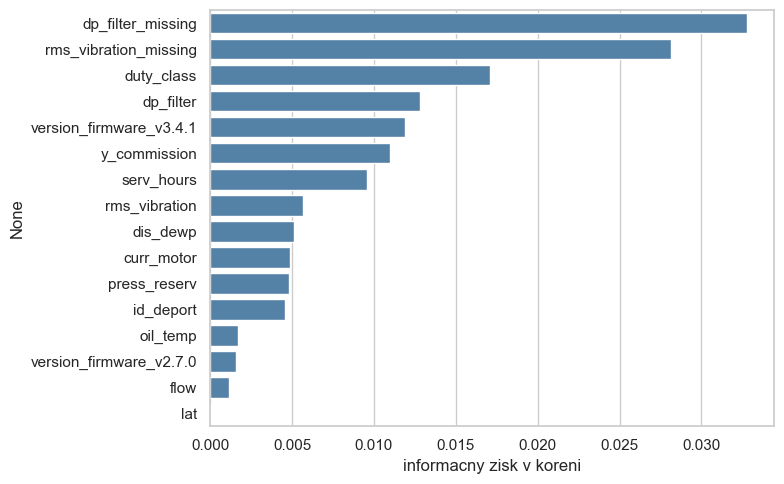

In [7]:
binovane = id3_pipeline()[:-1].fit_transform(train_X, train_y)
id3_pomocny = ID3Classifier()
zisk = pd.Series({c: id3_pomocny._gain(binovane[c].to_numpy(), train_y.to_numpy(), np.ones(len(train_y)))
                  for c in binovane.columns}).sort_values(ascending=False)
p = train_y.mean()
print("entropia ciela v koreni:", round(-(p * np.log2(p) + (1 - p) * np.log2(1 - p)), 4))

display(zisk.round(4).to_frame("informacny zisk").T)

plt.figure(figsize=(8, 5))
sns.barplot(x=zisk.values, y=zisk.index, color="steelblue")
plt.xlabel("informacny zisk v koreni"); plt.tight_layout(); plt.show()

Entropia cieľa v koreni je 0,529 bitu (asi 12 % porúch). Najviac ju znižujú príznaky chýbajúceho merania `dp_filter_missing` (0,033) a `rms_vibration_missing` (0,028), za nimi `duty_class` (0,017) a `dp_filter` (0,013). Poradie sa zhoduje s výberom atribútov z 2.2. Koreňom stromu bude `dp_filter_missing`.

Zisky sú v absolútnej hodnote malé: žiadny atribút sám poruchu neurčí, preto strom potrebuje viac úrovní.

In [8]:
id3_zaklad = id3_pipeline().fit(train_X, train_y)      # cisty ID3 bez obmedzeni
strom = id3_zaklad.named_steps["id3"]
print("hlbka (vratane korena):", strom.depth_, "| uzly:", strom.n_nodes_, "| listy:", strom.n_leaves_)
print("\nprve dve urovne pod korenom:")
vypis_strom(strom, max_uroven=3, bin_cols=BIN_COLS)

hlbka (vratane korena): 13 | uzly: 4192 | listy: 2908

prve dve urovne pod korenom:
dp_filter_missing = 0  [n=10610, porucha=10%]
    rms_vibration_missing = 0  [n=10229, porucha=9%]
    rms_vibration_missing = 1  [n=381, porucha=49%]
dp_filter_missing = 1  [n=406, porucha=57%]
    rms_vibration_missing = 0  [n=374, porucha=53%]
    rms_vibration_missing = 1  [n=32, porucha=97%]


Čistý ID3 bez obmedzení narástol do hĺbky 13 (požiadavka zadania na hĺbku aspoň 2 vrátane koreňa je splnená) a má 4 192 uzlov, z toho 2 908 listov. Na 11 016 trénovacích riadkov to vychádza na menej ako 4 riadky na list, čo je prvý signál, že si strom pamätá jednotlivé merania.

Prvé úrovne sú pritom zmysluplné: ak chýba `dp_filter`, podiel porúch je 57 % oproti 10 %, a ak chýbajú obe merania, až 97 % (32 riadkov). Platí predpoklad z fázy 2, že hodnota chýba skôr, než porucha nastane.

### Vyhodnotenie ID3

Porúch je asi 12 %, takže model "vždy bez poruchy" má accuracy 88 %, no je nepoužiteľný. Rozhodujeme preto podľa **recall**, **precision**, **F1**, **balanced accuracy**, **ROC-AUC** a **PR-AUC**; accuracy uvádzame len na porovnanie. Ako základnú líniu používame `DummyClassifier` (vždy "bez poruchy" a náhodné tipovanie).

Hodnotíme 5-násobnou CV na trénovacej množine delenou podľa `id_unit` (`StratifiedGroupKFold`), pričom sa celá pipeline v každom foldu učí nanovo.

In [9]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "balanced accuracy": "balanced_accuracy", "precision": "precision",
           "recall": "recall", "F1": "f1", "ROC-AUC": "roc_auc", "PR-AUC": "average_precision"}

def cv_vysledky(model):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")        # precision = 0/0, ked model v niektorom kroku nepredikuje ziadnu poruchu
        s = cross_validate(model, train_X, train_y, groups=train_groups, cv=cv, scoring=SCORING,
                           return_train_score=True, n_jobs=-1)
    return pd.DataFrame({"train": {m: s["train_" + m].mean() for m in SCORING},
                         "validacia": {m: s["test_" + m].mean() for m in SCORING},
                         "validacia std": {m: s["test_" + m].std() for m in SCORING}})

def metriky(model, X, y):
    pred, proba = model.predict(X), model.predict_proba(X)[:, 1]
    return pd.Series({"accuracy": accuracy_score(y, pred), "balanced accuracy": balanced_accuracy_score(y, pred),
                      "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
                      "F1": f1_score(y, pred), "ROC-AUC": roc_auc_score(y, proba),
                      "PR-AUC": average_precision_score(y, proba)})

vys_zaklad = cv_vysledky(id3_pipeline())
vys_zaklad["rozdiel"] = vys_zaklad["train"] - vys_zaklad["validacia"]
display(vys_zaklad.round(3))

,train,validacia,validacia std,rozdiel
accuracy,0.983,0.820,0.002,0.163
balanced accuracy,0.959,0.593,0.012,0.366
precision,0.930,0.270,0.013,0.660
recall,0.927,0.295,0.028,0.633
F1,0.929,0.282,0.019,0.647
ROC-AUC,0.962,0.609,0.011,0.353
PR-AUC,0.879,0.172,0.007,0.707


In [10]:
dummy_modely = {"vzdy bez poruchy": "most_frequent", "nahodny podla podielu tried": "stratified"}
vys_dummy = {n: cv_vysledky(Pipeline([("prep", build_pipeline()),
                                      ("dummy", DummyClassifier(strategy=s, random_state=RANDOM_STATE))]))["validacia"]
             for n, s in dummy_modely.items()}
display(pd.DataFrame({**vys_dummy, "cisty ID3": vys_zaklad["validacia"]}).round(3))

,vzdy bez poruchy,nahodny podla podielu tried,cisty ID3
accuracy,0.88,0.792,0.820
balanced accuracy,0.50,0.504,0.593
precision,0.00,0.126,0.270
recall,0.00,0.124,0.295
F1,0.00,0.125,0.282
ROC-AUC,0.50,0.504,0.609
PR-AUC,0.12,0.121,0.172


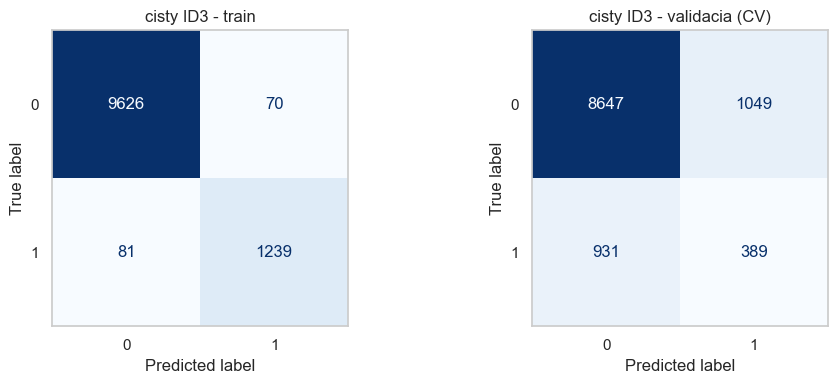

              precision    recall  f1-score   support

 bez poruchy      0.903     0.892     0.897      9696
     porucha      0.271     0.295     0.282      1320

    accuracy                          0.820     11016
   macro avg      0.587     0.593     0.590     11016
weighted avg      0.827     0.820     0.824     11016



In [11]:
# matica zamien z validacnych casti 
# kazdy riadok je predikovany modelom, ktory ho pri uceni nevidel
pred_val = cross_val_predict(id3_pipeline(), train_X, train_y, groups=train_groups, cv=cv, n_jobs=-1)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(train_y, id3_zaklad.predict(train_X), ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("cisty ID3 - train")
ConfusionMatrixDisplay.from_predictions(train_y, pred_val, ax=ax[1], cmap="Blues", colorbar=False)
ax[1].set_title("cisty ID3 - validacia (CV)")
for a in ax: a.grid(False)
plt.tight_layout(); plt.show()
print(classification_report(train_y, pred_val, target_names=["bez poruchy", "porucha"], digits=3))

**Vyhodnotenie čistého ID3.** Na trénovacích častiach vyzerá model takmer dokonale (F1 0,929; ROC-AUC 0,962), na validačných je slabý:

* zachytí iba 29,5 % porúch (recall) a z hlásených porúch je skutočných 27,0 % (precision), F1 = 0,282,
* accuracy 0,820 je nižšia než 0,880 modelu "vždy bez poruchy" (tabuľka základných línií vyššie), pričom ten má recall aj F1 rovné 0, takže accuracy tu o kvalite nič nehovorí,
* ROC-AUC 0,609 je len o málo lepšie než náhodné zoradenie (0,5) a PR-AUC 0,172 je len o 0,05 nad základnou líniou 0,12 (podiel porúch).

Výsledky sú medzi piatimi časťami stabilné (smerodajná odchýlka F1 0,019), takže nejde o náhodu jedného delenia.

### Overfitting

**Má ID3 overfit?** Porovnávame skóre na trénovacích a validačných častiach krížovej validácie. Ak je model na dátach, ktoré videl, výrazne lepší než na nových, naučil sa šum a nie vzťahy. Zložitosť stromu riadime hĺbkou, preto pre každú hĺbku meriame obe skóre.

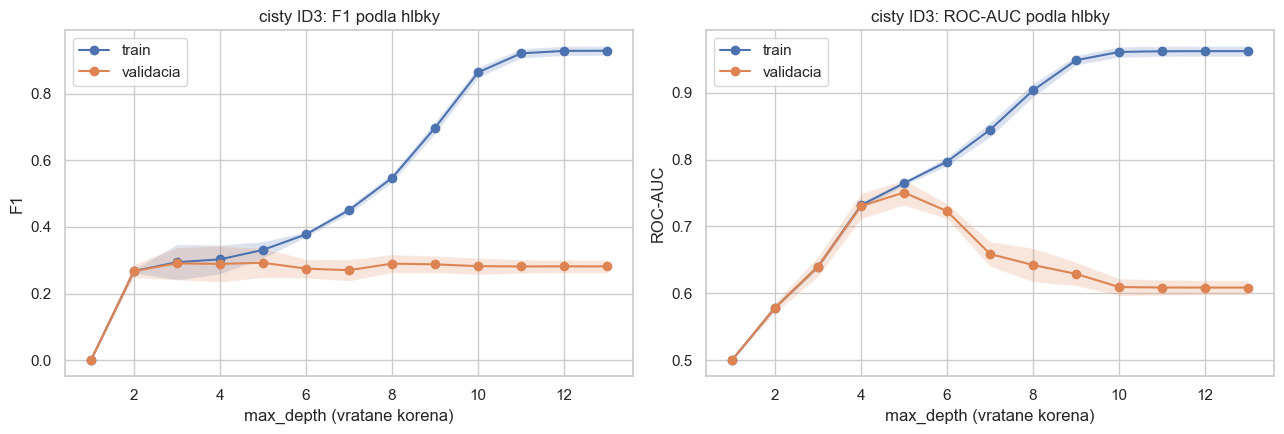

,F1 train,recall train,precision train,ROC-AUC train,F1 val,recall val,precision val,ROC-AUC val
max_depth,,,,,,,,
1,0.000,0.000,0.000,0.500,0.000,0.000,0.000,0.500
2,0.268,0.175,0.569,0.578,0.268,0.175,0.569,0.578
3,0.294,0.204,0.563,0.640,0.291,0.201,0.555,0.640
4,0.303,0.202,0.631,0.732,0.289,0.197,0.565,0.731
5,0.331,0.219,0.693,0.765,0.292,0.196,0.584,0.751
6,0.378,0.248,0.793,0.797,0.275,0.182,0.565,0.723
7,0.451,0.300,0.908,0.845,0.270,0.182,0.530,0.659
8,0.547,0.399,0.870,0.904,0.290,0.217,0.439,0.642
9,0.698,0.577,0.882,0.949,0.288,0.253,0.334,0.629


In [12]:
def grid(parametre):
    # GridSearchCV s viacerymi metrikami naraz
    # refit=False, zaujimaju nas vysledky z CV
    metriky_gs = {"F1": "f1", "recall": "recall", "precision": "precision", "ROC-AUC": "roc_auc"}
    gs = GridSearchCV(id3_pipeline(), {"id3__" + k: v for k, v in parametre.items()}, scoring=metriky_gs,
                      refit=False, cv=cv, return_train_score=True, n_jobs=-1)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        gs.fit(train_X, train_y, groups=train_groups)
    r = pd.DataFrame(gs.cv_results_)
    out = pd.DataFrame({k: r["param_id3__" + k] for k in parametre})
    for m in metriky_gs:
        out[f"{m} train"], out[f"{m} val"] = r[f"mean_train_{m}"], r[f"mean_test_{m}"]
        out[f"{m} train std"], out[f"{m} val std"] = r[f"std_train_{m}"], r[f"std_test_{m}"]
    return out

hlbky = list(range(1, 14))      # neobmedzeny strom ma hlbku 13, cize 13 = bez obmedzenia
krivka = grid({"max_depth": hlbky, "class_weight": [None, "balanced"]})
krivka["max_depth"] = krivka["max_depth"].astype(int)
krivka["class_weight"] = krivka["class_weight"].map(lambda v: "balanced" if v == "balanced" else "ziadne")

# priemer z foldov a pas +- smerodajna odchylka
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
k = krivka[krivka["class_weight"] == "ziadne"]
for a, m in zip(ax, ["F1", "ROC-AUC"]):
    for st, nazov in [("train", "train"), ("val", "validacia")]:
        a.plot(k["max_depth"], k[f"{m} {st}"], marker="o", label=nazov)
        a.fill_between(k["max_depth"], k[f"{m} {st}"] - k[f"{m} {st} std"], k[f"{m} {st}"] + k[f"{m} {st} std"],
                       alpha=0.2)
    a.set_title(f"cisty ID3: {m} podla hlbky"); a.set_xlabel("max_depth (vratane korena)")
    a.set_ylabel(m); a.legend()
plt.tight_layout(); plt.show()
stlpce = [f"{m} {st}" for st in ["train", "val"] for m in ["F1", "recall", "precision", "ROC-AUC"]]
display(k.set_index("max_depth")[stlpce].round(3))

**Áno, čistý ID3 má overfit.**

* Do hĺbky 5 idú obe krivky spolu (ROC-AUC 0,765 na train a 0,751 na validácii).
* Od hĺbky 6 trénovacie skóre ďalej rastie (F1 až 0,93, ROC-AUC 0,96), no validačné ROC-AUC klesá z 0,751 na 0,609 a validačné F1 sa drží okolo 0,28. Každá ďalšia úroveň teda pridáva pravidlá, ktoré platia len pre trénovacie riadky.
* Pri neobmedzenom strome je rozdiel medzi train a validáciou 0,65 v F1 a 0,35 v ROC-AUC.

Opačný problém vidno pri hĺbke 1 a 2: model je príliš jednoduchý (ROC-AUC 0,50 a 0,58), čo je underfit. Vhodná zložitosť je teda niekde okolo hĺbky 5.

**Riešenie.** Používame dve úpravy:

1. **Predčasné zastavenie (pre-pruning)** - obmedzíme hĺbku (`max_depth`) a najmenší uzol, ktorý sa ešte smie deliť (`min_samples_split`). Strom tak nemôže vytvárať listy pre jednotlivé riadky.
2. **Váhy tried** (`class_weight="balanced"`) - samotné orezanie overfit odstráni, ale plytký strom s väčšinovým hlasovaním takmer nikdy nepredikuje poruchu (listy s viac než 50 % porúch sú zriedkavé). Váhy vyrovnajú obe triedy v entropii aj v listoch.

Porovnanie oboch variantov pri rovnakej hĺbke:

In [13]:
por = krivka[krivka["max_depth"].isin([3, 4, 5, 6])].pivot(index="max_depth", columns="class_weight",
                                                       values=["recall val", "precision val", "F1 val", "ROC-AUC val"])
display(por.round(3))

recall val        precision val          F1 val         \
class_weight   balanced ziadne      balanced ziadne balanced ziadne   
max_depth                                                             
3                 0.317  0.201         0.531  0.555    0.396  0.291   
4                 0.739  0.197         0.202  0.565    0.318  0.289   
5                 0.652  0.196         0.251  0.584    0.362  0.292   
6                 0.552  0.182         0.268  0.565    0.361  0.275   

             ROC-AUC val         
class_weight    balanced ziadne  
max_depth                        
3                  0.640  0.640  
4                  0.731  0.731  
5                  0.752  0.751  
6                  0.718  0.723

Váhy takmer nemenia zoradenie pozorovaní (ROC-AUC), menia rozhodnutie v listoch: pri hĺbke 5 stúpne recall z 0,196 na 0,652 a F1 z 0,292 na 0,362, precision klesne z 0,584 na 0,251. Pri prediktívnej údržbe je prehliadnutá porucha drahšia než falošný poplach, preto vyvažujeme.

**Váhy alebo vzorkovanie?** Vyskúšame aj **oversampling** (duplikovanie porúch) a **undersampling** (vyhodenie riadkov bez poruchy). Vzorkujeme len trénovaciu časť každého foldu, inak by duplikáty prešli do validácie. Porovnávame pri `max_depth = 5`, `min_samples_split = 100`.

In [14]:
def cv_vzorkovanie(vytvor_model, metoda):
    # vzorkovanie iba na trenovacej casti kazdeho foldu; validacna cast ostava povodna
    vysledky = []
    for tr, va in cv.split(train_X, train_y, train_groups):
        X_tr, y_tr = train_X.iloc[tr], train_y.iloc[tr].to_numpy()
        if metoda in ("oversampling", "undersampling"):
            vacsina, mensina = X_tr[y_tr == 0], X_tr[y_tr == 1]
            if metoda == "oversampling":
                mensina = resample(mensina, replace=True, n_samples=len(vacsina), random_state=RANDOM_STATE)
            else:
                vacsina = resample(vacsina, replace=False, n_samples=len(mensina), random_state=RANDOM_STATE)
            X_tr = pd.concat([vacsina, mensina])
            y_tr = np.r_[np.zeros(len(vacsina), dtype=int), np.ones(len(mensina), dtype=int)]
        model = vytvor_model().fit(X_tr, y_tr)
        y_va, pred, proba = train_y.iloc[va], model.predict(train_X.iloc[va]), model.predict_proba(train_X.iloc[va])[:, 1]
        vysledky.append([f1_score(y_va, pred), recall_score(y_va, pred), precision_score(y_va, pred, zero_division=0),
                         roc_auc_score(y_va, proba), average_precision_score(y_va, proba)])
    return pd.Series(np.mean(vysledky, axis=0), index=["F1", "recall", "precision", "ROC-AUC", "PR-AUC"])

zaklad_param = dict(max_depth=5, min_samples_split=100)
vzorkovanie = pd.DataFrame({
    "bez uprav": cv_vzorkovanie(lambda: id3_pipeline(**zaklad_param), "bez"),
    "class_weight": cv_vzorkovanie(lambda: id3_pipeline(class_weight="balanced", **zaklad_param), "bez"),
    "oversampling": cv_vzorkovanie(lambda: id3_pipeline(**zaklad_param), "oversampling"),
    "undersampling": cv_vzorkovanie(lambda: id3_pipeline(**zaklad_param), "undersampling"),
}).T
display(vzorkovanie.round(3))

,F1,recall,precision,ROC-AUC,PR-AUC
bez uprav,0.300,0.205,0.571,0.755,0.358
class_weight,0.365,0.659,0.253,0.760,0.364
oversampling,0.362,0.637,0.253,0.749,0.356
undersampling,0.359,0.680,0.244,0.755,0.349


Všetky tri spôsoby vyvažovania dávajú podobný výsledok (F1 0,359 až 0,365, ROC-AUC 0,749 až 0,760); bez vyvažovania je recall len 0,205. Zvolíme `class_weight="balanced"`, lebo nič neduplikuje ani nevyhadzuje a je rýchle.

`max_depth` a `min_samples_split` vyberieme cez `GridSearchCV` (06_03): najlepšie validačné ROC-AUC spomedzi nastavení, kde sa train a validácia líšia najviac o 0,02 (v ROC-AUC aj F1).

In [15]:
mriezka = grid({"max_depth": [3, 4, 5, 6, 7, 8, 10], "min_samples_split": [2, 100, 200, 400],
                "class_weight": ["balanced"]})
mriezka[["max_depth", "min_samples_split"]] = mriezka[["max_depth", "min_samples_split"]].astype(int)
mriezka["rozdiel ROC-AUC"] = mriezka["ROC-AUC train"] - mriezka["ROC-AUC val"]
mriezka["rozdiel F1"] = mriezka["F1 train"] - mriezka["F1 val"]

# bez overfitu: train a validacia sa lisia najviac o 0,02; spomedzi nich najlepsie validacne ROC-AUC
bez_overfitu = mriezka[(mriezka["rozdiel ROC-AUC"] <= 0.02) & (mriezka["rozdiel F1"] <= 0.02)]
najlepsi = bez_overfitu.sort_values("ROC-AUC val", ascending=False, kind="stable").iloc[0]
stlpce = ["max_depth", "min_samples_split", "ROC-AUC train", "ROC-AUC val", "F1 train", "F1 val", "recall val",
          "rozdiel ROC-AUC", "rozdiel F1"]
display(mriezka.sort_values("ROC-AUC val", ascending=False)[stlpce].head(12).round(3))
print("vybrane nastavenie: max_depth =", int(najlepsi["max_depth"]), "| min_samples_split =", int(najlepsi["min_samples_split"]))

,max_depth,min_samples_split,ROC-AUC train,ROC-AUC val,F1 train,F1 val,recall val,rozdiel ROC-AUC,rozdiel F1
23,8,400,0.793,0.760,0.386,0.360,0.642,0.033,0.025
27,10,400,0.793,0.760,0.386,0.360,0.642,0.033,0.025
19,7,400,0.793,0.760,0.386,0.360,0.642,0.033,0.025
9,5,100,0.764,0.760,0.369,0.365,0.659,0.005,0.004
10,5,200,0.764,0.760,0.369,0.365,0.659,0.005,0.004
13,6,100,0.790,0.759,0.397,0.378,0.602,0.030,0.019
11,5,400,0.763,0.759,0.369,0.365,0.659,0.004,0.004
14,6,200,0.789,0.759,0.397,0.378,0.602,0.030,0.019
15,6,400,0.786,0.758,0.394,0.371,0.592,0.027,0.022
22,8,200,0.808,0.755,0.393,0.361,0.656,0.054,0.032


vybrane nastavenie: max_depth = 5 | min_samples_split = 100


Validačné ROC-AUC 0,760 dosahuje viac nastavení. Stromy s hĺbkou 7 až 10 a `min_samples_split = 400` ho dosahujú s rozdielom 0,033 medzi train a validáciou, strom s hĺbkou 5 a `min_samples_split = 100` s rozdielom 0,005. Volíme preto jednoduchší: **`max_depth = 5`, `min_samples_split = 100`, `class_weight = "balanced"`**.

In [16]:
PARAMS = dict(max_depth=int(najlepsi["max_depth"]), min_samples_split=int(najlepsi["min_samples_split"]),
              class_weight="balanced")
vys_final = cv_vysledky(id3_pipeline(**PARAMS))
vys_final["rozdiel"] = vys_final["train"] - vys_final["validacia"]

porovnanie = pd.concat({"cisty ID3": vys_zaklad[["train", "validacia", "rozdiel"]],
                        "upraveny ID3": vys_final[["train", "validacia", "rozdiel"]]}, axis=1)
display(porovnanie.round(3))

cisty ID3                   upraveny ID3                  
                      train validacia rozdiel        train validacia rozdiel
accuracy              0.983     0.820   0.163        0.727     0.725   0.002
balanced accuracy     0.959     0.593   0.366        0.700     0.697   0.003
precision             0.930     0.270   0.660        0.256     0.253   0.003
recall                0.927     0.295   0.633        0.663     0.659   0.004
F1                    0.929     0.282   0.647        0.369     0.365   0.004
ROC-AUC               0.962     0.609   0.353        0.764     0.760   0.005
PR-AUC                0.879     0.172   0.707        0.381     0.364   0.016

**Záverečné overenie na testovacej množine.** Upravený ID3 učíme na celej trénovacej množine a prvýkrát ho použijeme na testovacej, ktorú model ani výber parametrov nevideli.

hlbka (vratane korena): 5 | uzly: 41 | listy: 29


,cisty ID3 - train,cisty ID3 - test,upraveny ID3 - train,upraveny ID3 - test
accuracy,0.986,0.830,0.715,0.717
balanced accuracy,0.966,0.618,0.700,0.723
precision,0.947,0.306,0.248,0.257
recall,0.939,0.339,0.680,0.731
F1,0.943,0.322,0.364,0.380
ROC-AUC,0.968,0.635,0.764,0.788
PR-AUC,0.901,0.194,0.388,0.418


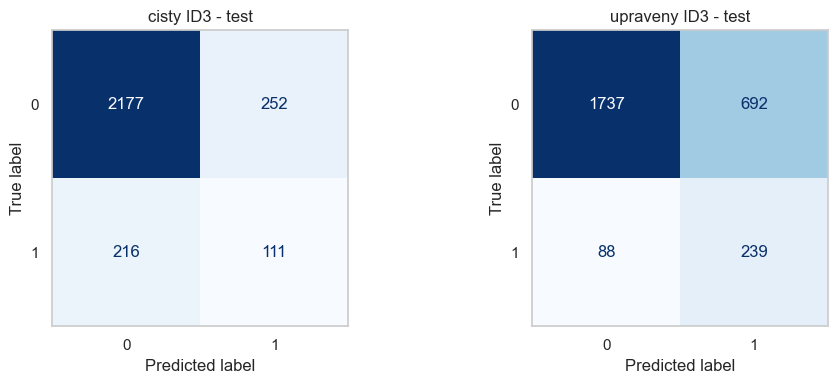

In [17]:
id3_final = id3_pipeline(**PARAMS).fit(train_X, train_y)
strom = id3_final.named_steps["id3"]
print("hlbka (vratane korena):", strom.depth_, "| uzly:", strom.n_nodes_, "| listy:", strom.n_leaves_)

tab = pd.DataFrame({"cisty ID3 - train": metriky(id3_zaklad, train_X, train_y),
                    "cisty ID3 - test": metriky(id3_zaklad, test_X, test_y),
                    "upraveny ID3 - train": metriky(id3_final, train_X, train_y),
                    "upraveny ID3 - test": metriky(id3_final, test_X, test_y)})
display(tab.round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(test_y, id3_zaklad.predict(test_X), ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("cisty ID3 - test")
ConfusionMatrixDisplay.from_predictions(test_y, id3_final.predict(test_X), ax=ax[1], cmap="Blues", colorbar=False)
ax[1].set_title("upraveny ID3 - test")
for a in ax: a.grid(False)
plt.tight_layout(); plt.show()

In [18]:
print("pravidla upraveneho ID3 (prve tri urovne pod korenom):")
vypis_strom(strom, max_uroven=4, bin_cols=BIN_COLS)

pravidla upraveneho ID3 (prve tri urovne pod korenom):
dp_filter_missing = 0  [n=10610, porucha=10%]
    rms_vibration_missing = 0  [n=10229, porucha=9%]
        duty_class = 1  [n=4040, porucha=14%]
        duty_class = 2  [n=3639, porucha=7%]
        duty_class = 3  [n=2550, porucha=4%]
    rms_vibration_missing = 1  [n=381, porucha=49%]
        serv_hours = Q1  [n=71, porucha=34%] -> porucha=1
        serv_hours = Q2  [n=86, porucha=41%] -> porucha=1
        serv_hours = Q3  [n=111, porucha=50%]
        serv_hours = Q4  [n=113, porucha=64%]
dp_filter_missing = 1  [n=406, porucha=57%]
    rms_vibration_missing = 0  [n=374, porucha=53%]
        y_commission = Q1  [n=93, porucha=69%] -> porucha=1
        y_commission = Q2  [n=91, porucha=51%] -> porucha=1
        y_commission = Q3  [n=70, porucha=50%] -> porucha=1
        y_commission = Q4  [n=120, porucha=46%]
    rms_vibration_missing = 1  [n=32, porucha=97%] -> porucha=1


Pri váhach tried list hlási poruchu, ak je v ňom podiel porúch vyšší než v celých dátach (asi 12 %), preto aj list s 34 % porúch dáva `fail=1`.

### Záver k 3.1

| | čistý ID3 | upravený ID3 |
|---|---|---|
| nastavenie | bez obmedzení | `max_depth=5`, `min_samples_split=100`, `class_weight="balanced"` |
| veľkosť | hĺbka 13, 4 192 uzlov | hĺbka 5, 41 uzlov |
| F1 train / test | 0,943 / 0,322 | 0,364 / 0,380 |
| ROC-AUC train / test | 0,968 / 0,635 | 0,764 / 0,788 |
| recall train / test | 0,939 / 0,339 | 0,680 / 0,731 |

* Implementovali sme ID3 (entropia, informačný zisk, kvartily) a hodnotili ho metrikami pre nevyvážené triedy v CV delenej podľa jednotiek.
* Čistý ID3 silno overfituje (F1 0,943 na train, 0,322 na teste). Po obmedzení hĺbky a uzla je strom stokrát menší a train, validácia aj test sedia (F1 0,364 / 0,365 / 0,380), takže overfit je odstránený a nejde ani o underfit. Váhy tried dávajú rovnaký výsledok ako over- a undersampling.

**Obmedzenie:** precision je 0,26 (tri zo štyroch hlásení sú falošné poplachy), čo je cena za recall 0,73 pri jednoduchom strome. V 3.2 porovnáme ID3 so `scikit-learn`.

## 3.2 Trénovanie a vyhodnotenie klasifikátorov strojového učenia

Používame rovnakú pipeline z fázy 2, 5-násobnú CV delenú podľa `id_unit` a rovnaké metriky ako v 3.1, takže výsledky sú s ID3 priamo porovnateľné. Test použijeme až na záver. Sklearn modely dostávajú spojité atribúty v pôvodnej (škálovanej) podobe, bez kvartilov.

**Pozor na hĺbku:** sklearn počíta koreň ako hĺbku 0, náš ID3 ako 1, preto `max_depth` nenastavujeme rovnako, ale podľa krivky zložitosti každého modelu.

### Stromový algoritmus: `DecisionTreeClassifier`

Sklearn strom je binárny (delí podľa prahu `atribút <= hodnota`), kým ID3 vetví podľa všetkých hodnôt atribútu. Skúsime strom s predvolenými parametrami a potom s váhami tried a obmedzením zložitosti (`max_depth`, `min_samples_leaf`), ako v 3.1. Hyperparametre dôkladne ladíme až v 3.3.

In [19]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

def sk_pipeline(model):
    return Pipeline([("prep", build_pipeline()), ("model", model)])

strom_varianty = {
    "bez obmedzeni": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "len vahy tried": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "hlbka 5 + vahy": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE),
    "hlbka 5 + list >= 100 + vahy": DecisionTreeClassifier(max_depth=5, min_samples_leaf=100,
                                                          class_weight="balanced", random_state=RANDOM_STATE),
}
vys_stromy = {n: cv_vysledky(sk_pipeline(m)) for n, m in strom_varianty.items()}
tab = pd.DataFrame({n: v.loc[["F1", "recall", "precision", "ROC-AUC"], ["train", "validacia"]].stack()
                    for n, v in vys_stromy.items()}).T
tab.columns = [f"{m} {c}" for m, c in tab.columns]
tab["rozdiel ROC-AUC"] = tab["ROC-AUC train"] - tab["ROC-AUC validacia"]
display(tab.round(3))

,F1 train,F1 validacia,recall train,recall validacia,precision train,precision validacia,ROC-AUC train,ROC-AUC validacia,rozdiel ROC-AUC
bez obmedzeni,0.930,0.303,0.926,0.323,0.935,0.286,0.958,0.606,0.352
len vahy tried,0.918,0.276,0.919,0.276,0.918,0.279,0.954,0.589,0.365
hlbka 5 + vahy,0.414,0.380,0.635,0.573,0.308,0.288,0.781,0.742,0.040
hlbka 5 + list >= 100 + vahy,0.408,0.388,0.636,0.595,0.302,0.291,0.778,0.759,0.019


**Strom bez obmedzení overfituje rovnako ako čistý ID3:** na train F1 0,930 a ROC-AUC 0,958, na validácii F1 0,303 a ROC-AUC 0,606. Samotné váhy tried to nevyriešia (validačné ROC-AUC 0,589).

Obmedzením zložitosti sa train a validácia zblížia: hĺbka 5 s váhami a listom aspoň 100 riadkov má rozdiel ROC-AUC len 0,019 (0,778 na train, 0,759 na validácii; F1 0,408 a 0,388). Používame **`max_depth=5`, `min_samples_leaf=100`, `class_weight="balanced"`** (13 listov). Nejde o underfit, strom je lepší než neobmedzený aj než plytké stromy.

**Entropia alebo Gini?** ID3 používa entropiu, sklearn predvolene Giniho index, preto overíme, či výber kritéria na našich dátach niečo mení.

In [20]:
kriteria = {k: cv_vysledky(sk_pipeline(DecisionTreeClassifier(criterion=k, max_depth=5, min_samples_leaf=100,
                                                              class_weight="balanced", random_state=RANDOM_STATE)))
            for k in ["gini", "entropy"]}
tab = pd.DataFrame({k: v.loc[["F1", "recall", "precision", "ROC-AUC"], "validacia"] for k, v in kriteria.items()}).T
tab["rozdiel train - val (ROC-AUC)"] = [v.loc["ROC-AUC", "train"] - v.loc["ROC-AUC", "validacia"]
                                          for v in kriteria.values()]
display(tab.round(3))

,F1,recall,precision,ROC-AUC,rozdiel train - val (ROC-AUC)
gini,0.388,0.595,0.291,0.759,0.019
entropy,0.391,0.590,0.296,0.759,0.019


Kritériá dávajú takmer rovnaký výsledok (ROC-AUC 0,759 pri oboch, F1 0,388 a 0,391), ponechávame predvolený `gini`.

**Krivka zložitosti.** Postupne zvyšujeme `max_depth` a sledujeme skóre na trénovacích a validačných častiach CV (pás je smerodajná odchýlka z piatich foldov). Strom má len váhy tried, aby bol overfit viditeľný.

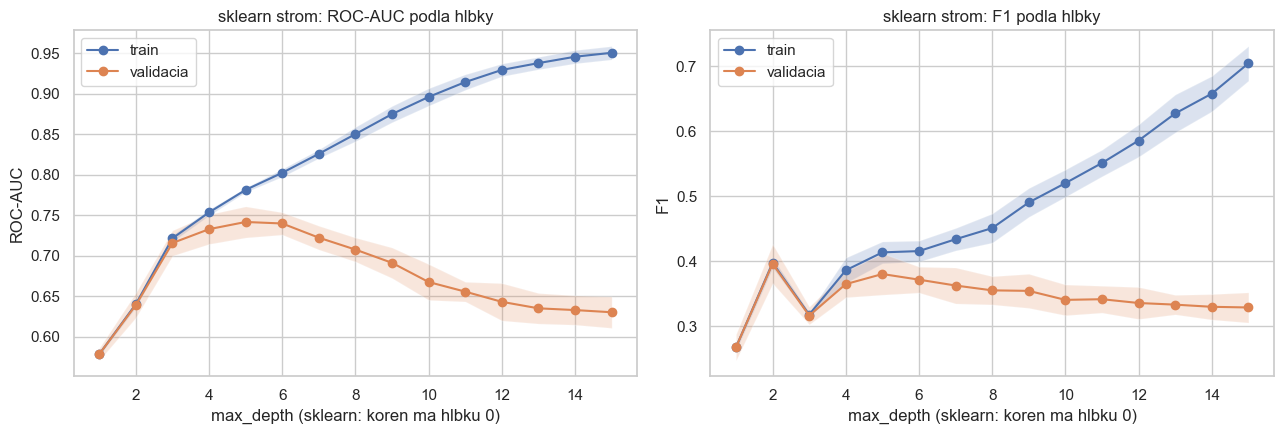

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
train,0.578,0.640,0.722,0.753,0.781,0.802,0.826,0.850,0.875,0.896,0.914,0.929,0.938,0.946,0.95
validacia,0.578,0.639,0.716,0.733,0.742,0.740,0.722,0.708,0.691,0.668,0.656,0.643,0.635,0.633,0.63


In [21]:
hlbky_sk = list(range(1, 16))
strom_bez_limitu = sk_pipeline(DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for a, (nazov, metrika) in zip(ax, [("ROC-AUC", "roc_auc"), ("F1", "f1")]):
    tr_s, va_s = validation_curve(strom_bez_limitu, train_X, train_y, groups=train_groups, cv=cv,
                                  param_name="model__max_depth", param_range=hlbky_sk, scoring=metrika, n_jobs=-1)
    for hodnoty, popis in [(tr_s, "train"), (va_s, "validacia")]:
        m_, s_ = hodnoty.mean(axis=1), hodnoty.std(axis=1)
        a.plot(hlbky_sk, m_, marker="o", label=popis)
        a.fill_between(hlbky_sk, m_ - s_, m_ + s_, alpha=0.2)
    a.set_title(f"sklearn strom: {nazov} podla hlbky"); a.set_xlabel("max_depth (sklearn: koren ma hlbku 0)")
    a.set_ylabel(nazov); a.legend()
    if metrika == "roc_auc":
        krivka_roc = pd.DataFrame({"train": tr_s.mean(axis=1), "validacia": va_s.mean(axis=1)}, index=hlbky_sk)
plt.tight_layout(); plt.show()
display(krivka_roc.T.round(3))

Krivka má rovnaký tvar ako pri ID3: validačné ROC-AUC je najvyššie pri hĺbke 5 (0,742) a potom klesá na 0,630 pri hĺbke 15, kým trénovacie rastie na 0,950. Minimálna veľkosť listu 100 ho posunie z 0,742 na 0,759.

**Post-pruning.** Druhá cesta proti overfitu je nechať strom narásť a dodatočne ho orezať (cost-complexity pruning): `ccp_alpha` je prah, pod ktorým sa vetvy orežú. Alfu vyberáme krížovou validáciou na trénovacej množine rovnakým pravidlom ako v 3.1 (najlepšie validačné ROC-AUC pri rozdiele train - validácia najviac 0,02 v ROC-AUC aj F1).

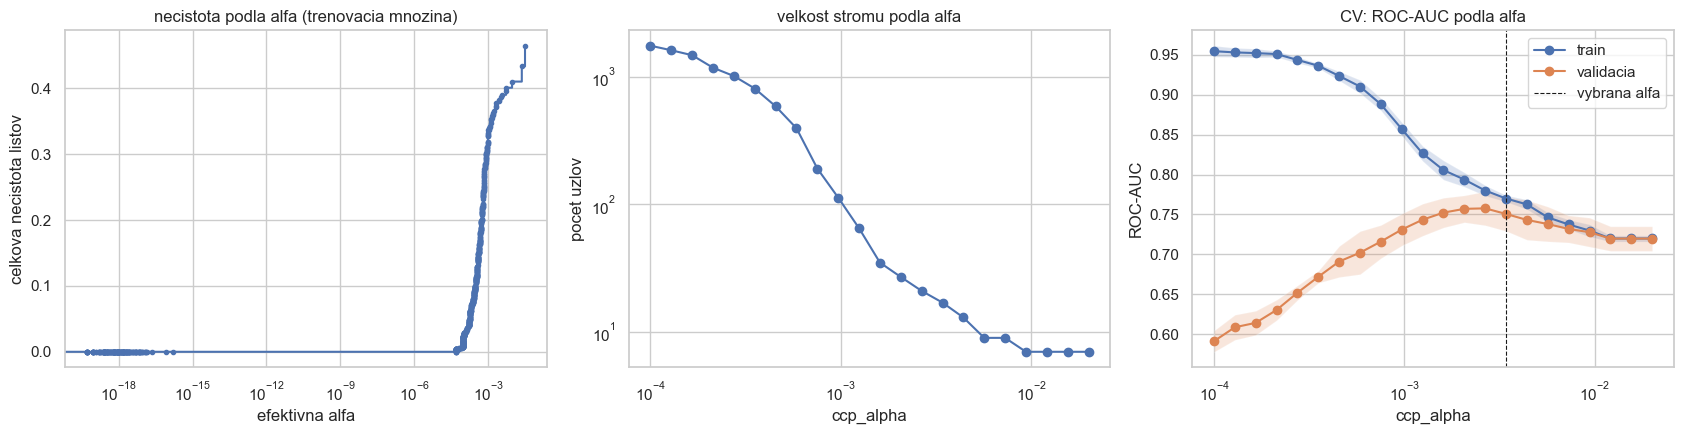

,alfa,uzly,hlbka,ROC-AUC train,ROC-AUC val,F1 train,F1 val,rozdiel ROC-AUC,rozdiel F1
0,0.0001,1751,31,0.9542,0.5916,0.9040,0.2848,0.3626,0.6192
1,0.0001,1613,29,0.9527,0.6090,0.8416,0.3037,0.3437,0.5380
2,0.0002,1475,25,0.9518,0.6145,0.8218,0.3103,0.3373,0.5115
3,0.0002,1177,24,0.9506,0.6306,0.7856,0.3309,0.3200,0.4548
4,0.0003,1013,24,0.9433,0.6522,0.7344,0.3491,0.2911,0.3852
5,0.0004,809,24,0.9360,0.6721,0.6696,0.3526,0.2639,0.3170
6,0.0005,587,20,0.9232,0.6912,0.6077,0.3573,0.2320,0.2504
7,0.0006,395,17,0.9100,0.7022,0.5575,0.3574,0.2077,0.2002
8,0.0008,191,14,0.8878,0.7161,0.5007,0.3552,0.1716,0.1454
9,0.0010,113,13,0.8569,0.7311,0.4617,0.3638,0.1257,0.0979


vybrana alfa: 0.00342 | uzly: 17


In [22]:
X_prep = build_pipeline().fit_transform(train_X, train_y)
cesta = DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE).cost_complexity_pruning_path(X_prep, train_y)

alfy = np.geomspace(1e-4, 2e-2, 22)
orezane = [DecisionTreeClassifier(class_weight="balanced", ccp_alpha=a, random_state=RANDOM_STATE).fit(X_prep, train_y).tree_
           for a in alfy]
strom_orez = sk_pipeline(DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))
tr_r, va_r = validation_curve(strom_orez, train_X, train_y, groups=train_groups, cv=cv, param_name="model__ccp_alpha",
                              param_range=alfy, scoring="roc_auc", n_jobs=-1)
tr_f, va_f = validation_curve(strom_orez, train_X, train_y, groups=train_groups, cv=cv, param_name="model__ccp_alpha",
                              param_range=alfy, scoring="f1", n_jobs=-1)
orezanie = pd.DataFrame({"alfa": alfy, "uzly": [t.node_count for t in orezane], "hlbka": [t.max_depth for t in orezane],
                         "ROC-AUC train": tr_r.mean(axis=1), "ROC-AUC val": va_r.mean(axis=1),
                         "F1 train": tr_f.mean(axis=1), "F1 val": va_f.mean(axis=1)})
orezanie["rozdiel ROC-AUC"] = orezanie["ROC-AUC train"] - orezanie["ROC-AUC val"]
orezanie["rozdiel F1"] = orezanie["F1 train"] - orezanie["F1 val"]
bez_overfitu_alfa = orezanie[(orezanie["rozdiel ROC-AUC"] <= 0.02) & (orezanie["rozdiel F1"] <= 0.02)]
vybrana_alfa = bez_overfitu_alfa.sort_values("ROC-AUC val", ascending=False, kind="stable").iloc[0]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(cesta.ccp_alphas[:-1], cesta.impurities[:-1], marker=".", drawstyle="steps-post")
ax[0].set_xscale("log"); ax[0].set_xlabel("efektivna alfa"); ax[0].set_ylabel("celkova necistota listov")
ax[0].set_title("necistota podla alfa (trenovacia mnozina)")
ax[1].plot(alfy, orezanie["uzly"], marker="o", label="pocet uzlov"); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("ccp_alpha"); ax[1].set_ylabel("pocet uzlov"); ax[1].set_title("velkost stromu podla alfa")
for hodnoty, popis in [(tr_r, "train"), (va_r, "validacia")]:
    m_, s_ = hodnoty.mean(axis=1), hodnoty.std(axis=1)
    ax[2].plot(alfy, m_, marker="o", label=popis); ax[2].fill_between(alfy, m_ - s_, m_ + s_, alpha=0.2)
ax[2].axvline(vybrana_alfa["alfa"], color="k", ls="--", lw=0.8, label="vybrana alfa")
ax[2].set_xscale("log"); ax[2].set_xlabel("ccp_alpha"); ax[2].set_ylabel("ROC-AUC"); ax[2].legend()
ax[2].set_title("CV: ROC-AUC podla alfa")
plt.tight_layout(); plt.show()

display(orezanie.round(4))
print("vybrana alfa:", round(vybrana_alfa["alfa"], 5), "| uzly:", int(vybrana_alfa["uzly"]))

In [23]:
vys_orez = cv_vysledky(sk_pipeline(DecisionTreeClassifier(class_weight="balanced", ccp_alpha=vybrana_alfa["alfa"],
                                                          random_state=RANDOM_STATE)))
pre = vys_stromy["hlbka 5 + list >= 100 + vahy"]
porovnanie_orez = pd.DataFrame({"pre-pruning (hlbka 5, list >= 100)": pre["validacia"],
                                "post-pruning (ccp_alpha)": vys_orez["validacia"]})
porovnanie_orez.loc["rozdiel train - val (ROC-AUC)"] = [pre.loc["ROC-AUC", "train"] - pre.loc["ROC-AUC", "validacia"],
                                                        vys_orez.loc["ROC-AUC", "train"] - vys_orez.loc["ROC-AUC", "validacia"]]
display(porovnanie_orez.round(3))

,"pre-pruning (hlbka 5, list >= 100)",post-pruning (ccp_alpha)
accuracy,0.773,0.775
balanced accuracy,0.696,0.692
precision,0.291,0.293
recall,0.595,0.583
F1,0.388,0.386
ROC-AUC,0.759,0.751
PR-AUC,0.346,0.335
rozdiel train - val (ROC-AUC),0.019,0.019


Post-pruning má rovnaký efekt ako obmedzenie hĺbky: s rastúcou alfou strom klesne z 1751 uzlov na desiatky a rozdiel train - validácia sa zmenší. Podľa nášho pravidla vyšla alfa 0,0034 (17 uzlov, validačné ROC-AUC 0,751, F1 0,386). Pre-pruning (hĺbka 5, list aspoň 100) je o niečo lepší (ROC-AUC 0,759, F1 0,388), preto ostáva finálnym stromom.

### Nestromový algoritmus: logistická regresia

Používame lineárnu `LogisticRegression` ako kontrast k stromom. Atribúty sú už vhodne upravené (spojité štandardizované, ostatné 0/1) a triedy vyvažujeme `class_weight="balanced"`. Citlivosť na regularizáciu `C` overíme na štyroch hodnotách.

In [24]:
riadky = []
for C in [0.01, 0.1, 1, 10]:
    v = cv_vysledky(sk_pipeline(LogisticRegression(C=C, class_weight="balanced", max_iter=2000)))
    riadky.append({"C": C, "ROC-AUC train": v.loc["ROC-AUC", "train"], "ROC-AUC validacia": v.loc["ROC-AUC", "validacia"],
                   "F1 train": v.loc["F1", "train"], "F1 validacia": v.loc["F1", "validacia"],
                   "recall validacia": v.loc["recall", "validacia"]})
display(pd.DataFrame(riadky).set_index("C").round(3))

,ROC-AUC train,ROC-AUC validacia,F1 train,F1 validacia,recall validacia
C,,,,,
0.01,0.803,0.800,0.399,0.398,0.709
0.10,0.811,0.807,0.414,0.415,0.699
1.00,0.811,0.808,0.420,0.419,0.695
10.00,0.811,0.808,0.420,0.419,0.695


Logistická regresia je na `C` takmer necitlivá (validačné ROC-AUC 0,800 až 0,808, rozdiel train - validácia najviac 0,008), overfit nehrozí. Ponechávame `C = 1`.

**Únik informácie pri výbere atribútov.** Atribúty z fázy 2 sme vybrali na celej trénovacej množine, teda aj z riadkov, ktoré sú pri CV vo validačnej časti, čo môže skóre mierne nadsadiť. Porovnáme s logistickou regresiou: 16 atribútov z 2.2, všetky atribúty a `SelectKBest(k=16)` vnútri pipeline.

In [25]:
lr = lambda: LogisticRegression(class_weight="balanced", max_iter=2000)
pocet_vsetkych = build_pipeline(vyber=None).fit_transform(train_X, train_y).shape[1]
varianty_vyberu = {
    "16 atributov z 2.2 (pevny vyber)": sk_pipeline(lr()),
    f"vsetky atributy ({pocet_vsetkych})": Pipeline([("prep", build_pipeline(vyber=None)), ("model", lr())]),
    "SelectKBest(k=16) v pipeline": Pipeline([("prep", build_pipeline(vyber=None)),
                                              ("select", SelectKBest(f_classif, k=16)), ("model", lr())]),
}
vys_vyber = pd.DataFrame({n: cv_vysledky(m).loc[["F1", "recall", "precision", "ROC-AUC"], "validacia"]
                          for n, m in varianty_vyberu.items()}).T
display(vys_vyber.round(3))

,F1,recall,precision,ROC-AUC
16 atributov z 2.2 (pevny vyber),0.419,0.695,0.300,0.808
vsetky atributy (31),0.417,0.695,0.298,0.806
SelectKBest(k=16) v pipeline,0.419,0.699,0.300,0.808


Rozdiely sú len 0,002 v ROC-AUC (0,808 / 0,806 / 0,808), takže výber z 2.2 CV nezvýhodňuje a ponechávame ho.

### Porovnanie s ID3 z 3.1

Všetky modely hodnotíme rovnako: najprv v krížovej validácii na trénovacej množine (rozhodujúce), potom raz na testovacej množine (záverečné overenie).

In [26]:
final_strom = sk_pipeline(strom_varianty["hlbka 5 + list >= 100 + vahy"])
final_logreg = sk_pipeline(LogisticRegression(C=1, class_weight="balanced", max_iter=2000))

vys_cv = {"ID3 cisty": vys_zaklad, "ID3 upraveny": vys_final,
          "strom sklearn (bez obmedzeni)": vys_stromy["bez obmedzeni"],
          "strom sklearn (upraveny)": vys_stromy["hlbka 5 + list >= 100 + vahy"],
          "logisticka regresia": cv_vysledky(final_logreg)}
cv_tab = pd.DataFrame({n: v["validacia"] for n, v in vys_cv.items()})
cv_gap = pd.DataFrame({n: (v["train"] - v["validacia"]) for n, v in vys_cv.items()}).loc[["F1", "ROC-AUC"]]
cv_gap.index = ["rozdiel train - val: F1", "rozdiel train - val: ROC-AUC"]
print("Krizova validacia (validacne casti):")
display(pd.concat([cv_tab, cv_gap]).round(3))

Krizova validacia (validacne casti):


,ID3 cisty,ID3 upraveny,strom sklearn (bez obmedzeni),strom sklearn (upraveny),logisticka regresia
accuracy,0.820,0.725,0.822,0.773,0.768
balanced accuracy,0.593,0.697,0.606,0.696,0.737
precision,0.270,0.253,0.286,0.291,0.300
recall,0.295,0.659,0.323,0.595,0.695
F1,0.282,0.365,0.303,0.388,0.419
ROC-AUC,0.609,0.760,0.606,0.759,0.808
PR-AUC,0.172,0.364,0.174,0.346,0.486
rozdiel train - val: F1,0.647,0.004,0.627,0.020,0.001
rozdiel train - val: ROC-AUC,0.353,0.005,0.352,0.019,0.003


In [27]:
final_strom.fit(train_X, train_y)
final_logreg.fit(train_X, train_y)
test_modely = {"ID3 cisty": id3_zaklad, "ID3 upraveny": id3_final,
               "strom sklearn (upraveny)": final_strom, "logisticka regresia": final_logreg}
test_tab = pd.DataFrame({n: metriky(m, test_X, test_y) for n, m in test_modely.items()})
print("Testovacia mnozina:")
display(test_tab.round(3))

Testovacia mnozina:


,ID3 cisty,ID3 upraveny,strom sklearn (upraveny),logisticka regresia
accuracy,0.830,0.717,0.798,0.771
balanced accuracy,0.618,0.723,0.720,0.762
precision,0.306,0.257,0.318,0.309
recall,0.339,0.731,0.618,0.749
F1,0.322,0.380,0.420,0.437
ROC-AUC,0.635,0.788,0.788,0.838
PR-AUC,0.194,0.418,0.358,0.518


**Krížová validácia (rozhodujúca).**

* **Neobmedzené modely overfitujú rovnako:** čistý ID3 aj neobmedzený sklearn strom majú validačné ROC-AUC 0,609 a 0,606 (rozdiel train - validácia 0,35). Rozhoduje obmedzenie zložitosti, nie typ vetvenia.
* **Upravený ID3 a upravený sklearn strom sú vyrovnané:** ROC-AUC 0,760 a 0,759, F1 0,365 a 0,388. ID3 zachytí viac porúch (recall 0,659 oproti 0,595), sklearn strom je presnejší (precision 0,291 oproti 0,253) a menší (13 listov oproti 29).
* **Logistická regresia je najlepšia:** ROC-AUC 0,808, PR-AUC 0,486 (stromy 0,35 až 0,36), F1 0,418, recall 0,695. Vzťahy v dátach sú skôr plynulé a aditívne, čo plytký strom aproximuje len schodmi.

**Test (záverečné overenie).** Poradie ostáva: logistická regresia ROC-AUC 0,838, F1 0,437, PR-AUC 0,518; oba stromy ROC-AUC 0,788. Skóre sú o niečo vyššie než v CV, čo je pri jednej testovacej množine bežné kolísanie, nie únik dát (test sa pri ladení nepoužil).

### Vizualizácia natrénovaných pravidiel

Sklearn strom zobrazíme ako graf a text (prvé tri úrovne). Pri logistickej regresii sú pravidlami koeficienty: ukazujú, ktoré atribúty pravdepodobnosť poruchy zvyšujú alebo znižujú.

hlbka: 5 | listy: 13


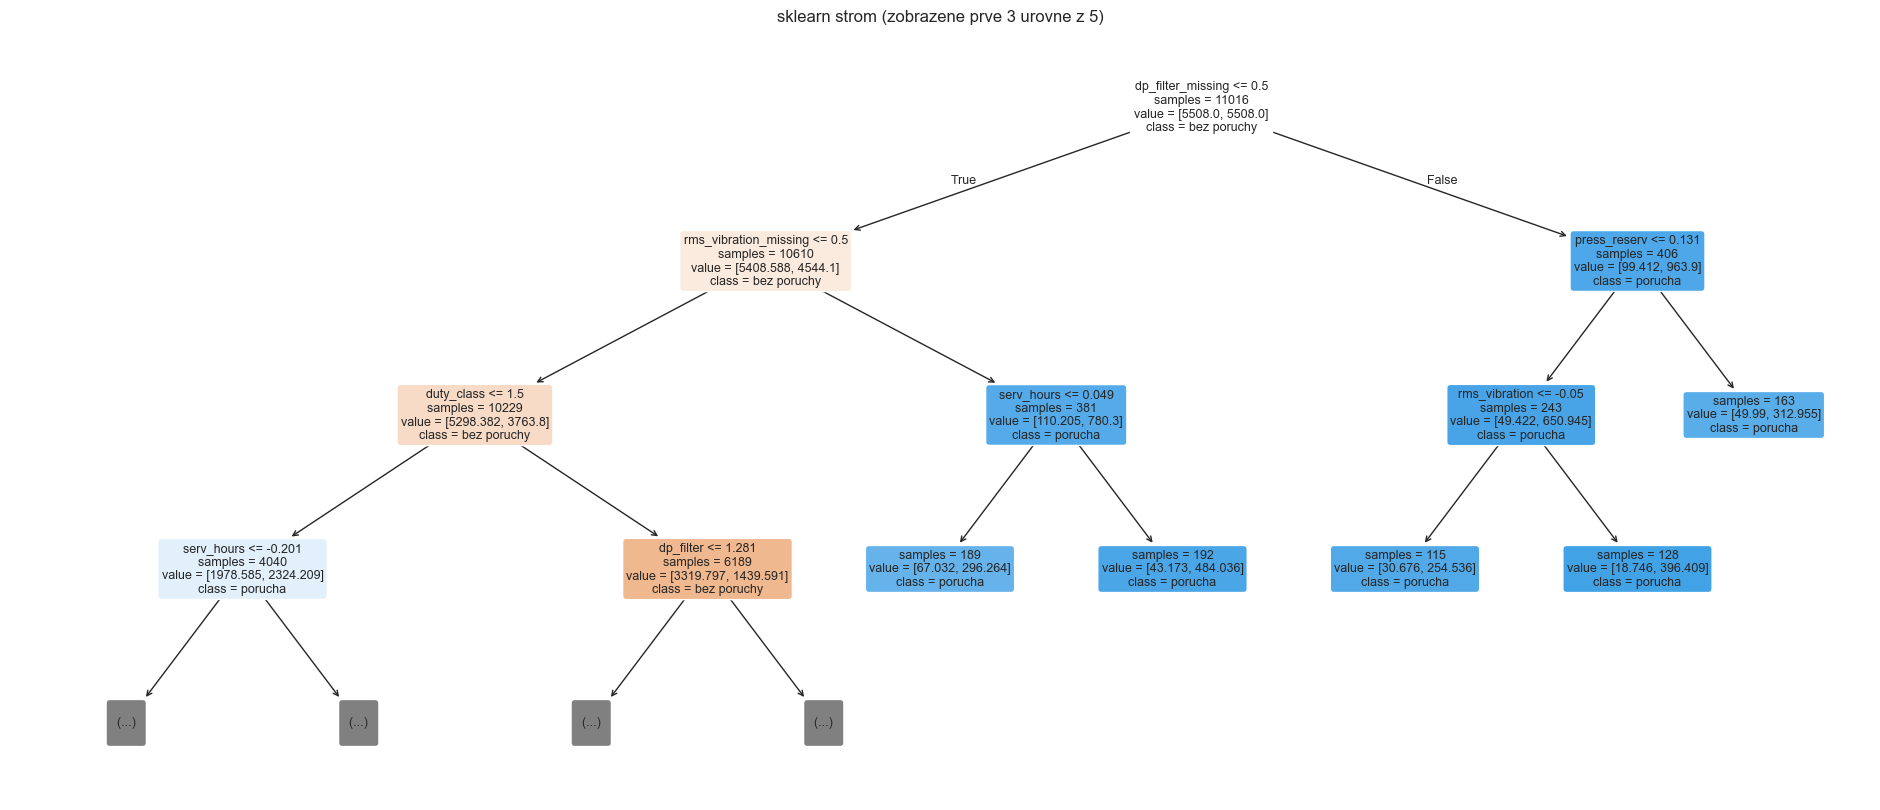

In [28]:
nazvy = list(final_strom.named_steps["prep"].transform(train_X.head(5)).columns)
strom_sk = final_strom.named_steps["model"]
print("hlbka:", strom_sk.get_depth(), "| listy:", strom_sk.get_n_leaves())

plt.figure(figsize=(24, 10))
plot_tree(strom_sk, max_depth=3, feature_names=nazvy, class_names=["bez poruchy", "porucha"],
          filled=True, rounded=True, impurity=False, proportion=False, fontsize=9)
plt.title("sklearn strom (zobrazene prve 3 urovne z 5)")
plt.show()

In [29]:
print(export_text(strom_sk, feature_names=nazvy, max_depth=3, show_weights=False))

|--- dp_filter_missing <= 0.50
|   |--- rms_vibration_missing <= 0.50
|   |   |--- duty_class <= 1.50
|   |   |   |--- serv_hours <= -0.20
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- serv_hours >  -0.20
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- duty_class >  1.50
|   |   |   |--- dp_filter <= 1.28
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- dp_filter >  1.28
|   |   |   |   |--- truncated branch of depth 2
|   |--- rms_vibration_missing >  0.50
|   |   |--- serv_hours <= 0.05
|   |   |   |--- class: 1
|   |   |--- serv_hours >  0.05
|   |   |   |--- class: 1
|--- dp_filter_missing >  0.50
|   |--- press_reserv <= 0.13
|   |   |--- rms_vibration <= -0.05
|   |   |   |--- class: 1
|   |   |--- rms_vibration >  -0.05
|   |   |   |--- class: 1
|   |--- press_reserv >  0.13
|   |   |--- class: 1



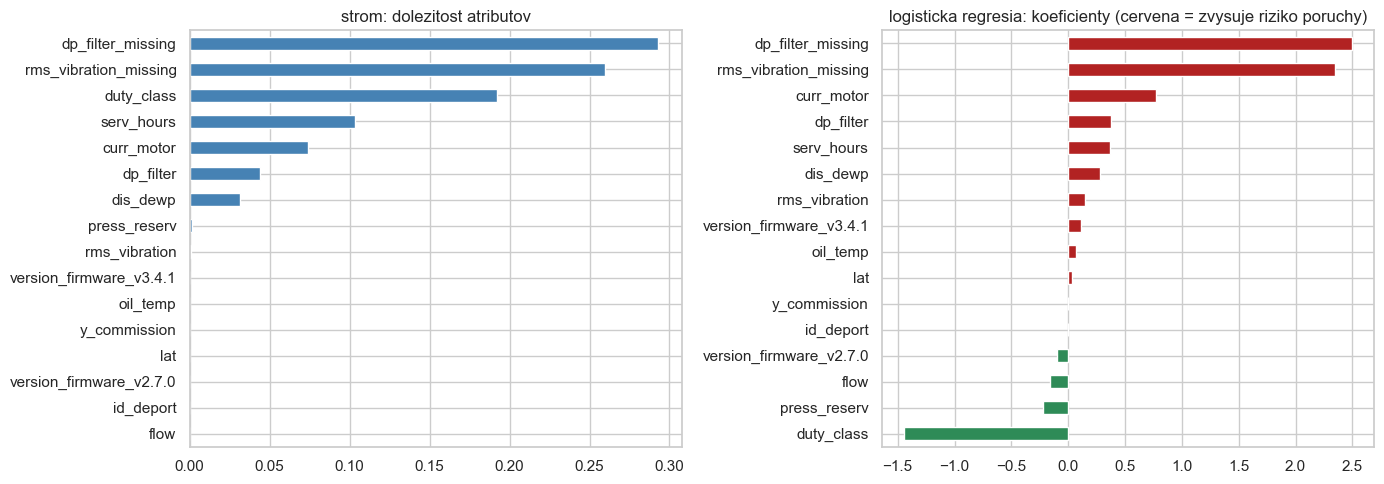

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
imp = pd.Series(strom_sk.feature_importances_, index=nazvy).sort_values()
imp.plot.barh(ax=ax[0], color="steelblue"); ax[0].set_title("strom: dolezitost atributov")

koef = pd.Series(final_logreg.named_steps["model"].coef_[0], index=nazvy).sort_values()
koef.plot.barh(ax=ax[1], color=np.where(koef > 0, "firebrick", "seagreen"))
ax[1].set_title("logisticka regresia: koeficienty (cervena = zvysuje riziko poruchy)")
plt.tight_layout(); plt.show()

**Pravidlá stromu.** Koreň je `dp_filter_missing`, rovnako ako v ID3. Ak merania chýbajú (`dp_filter_missing`, `rms_vibration_missing`), strom predikuje poruchu. Pri úplných meraniach (10 229 riadkov) rozhodujú `duty_class`, `serv_hours` a `dp_filter`. Dôležitosť atribútov: `dp_filter_missing` 0,29, `rms_vibration_missing` 0,26, `duty_class` 0,19, `serv_hours` 0,10, `curr_motor` 0,07.

**Koeficienty logistickej regresie.** Najsilnejšie kladne pôsobia príznaky chýbajúcich meraní (asi +2,5 a +2,3), záporne `duty_class` (-1,4): vyššia trieda zaťaženia znamená menej porúch. `curr_motor` má v regresii veľký kladný koeficient, no strom ho využíva málo.

**Upozornenie:** príznaky chýbania sú najsilnejšie atribúty všetkých modelov a predpokladajú, že hodnota chýba pred poruchou, čo z dát nevieme overiť.

### Vyhodnotenie modelov

Na teste porovnáme matice zámen (rozhodnutie pri prahu 0,5) a krivky ROC a Precision-Recall (kvalita zoradenia, nezávisle od prahu).

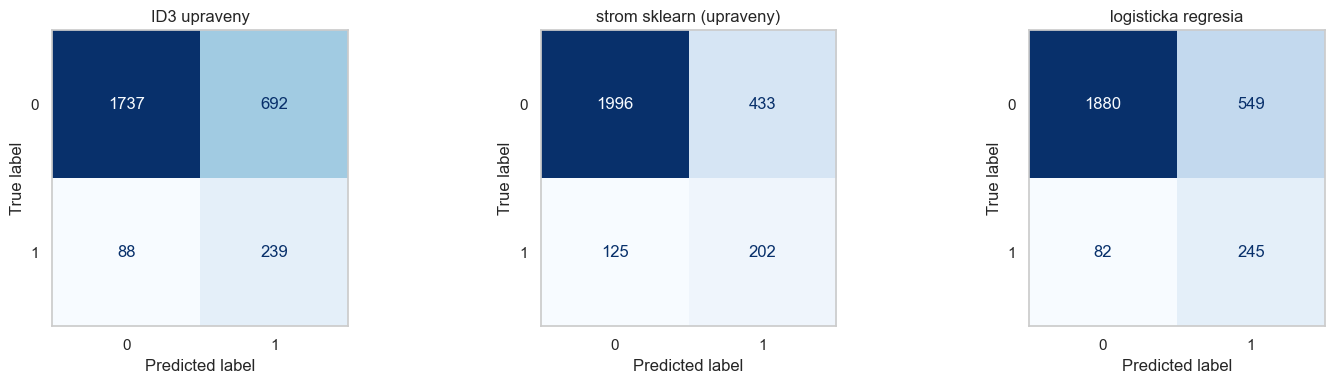

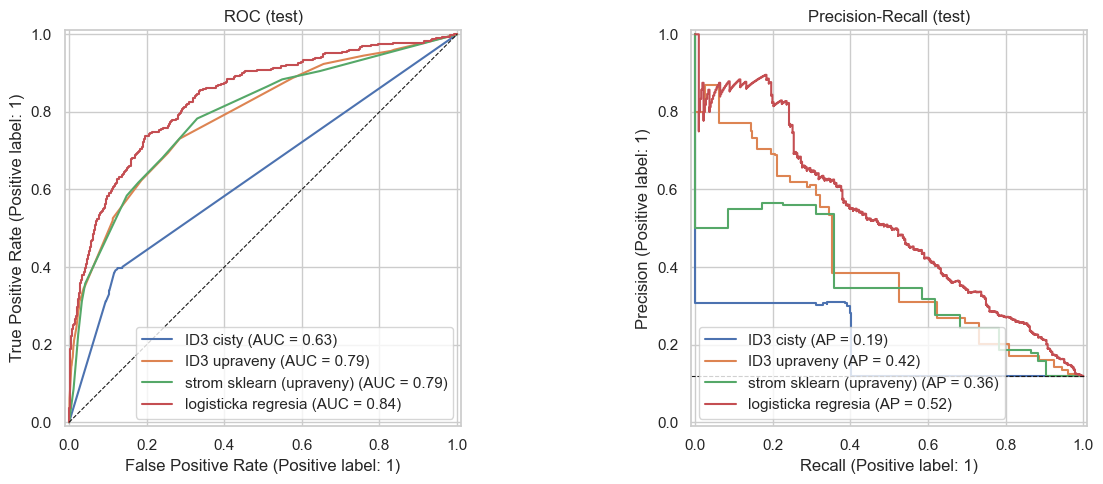

In [31]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (n, m) in zip(ax, [("ID3 upraveny", id3_final), ("strom sklearn (upraveny)", final_strom),
                          ("logisticka regresia", final_logreg)]):
    ConfusionMatrixDisplay.from_predictions(test_y, m.predict(test_X), ax=a, cmap="Blues", colorbar=False)
    a.set_title(n); a.grid(False)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n, m in test_modely.items():
    RocCurveDisplay.from_predictions(test_y, m.predict_proba(test_X)[:, 1], name=n, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(test_y, m.predict_proba(test_X)[:, 1], name=n, ax=ax[1])
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set_title("ROC (test)")
ax[1].axhline(test_y.mean(), color="k", ls="--", lw=0.8); ax[1].set_title("Precision-Recall (test)")
plt.tight_layout(); plt.show()

**Matice zámen (test, 327 skutočných porúch).** Logistická regresia zachytí 245 porúch (recall 0,749) pri 549 falošných poplachoch. Upravený ID3 zachytí 239 porúch pri 692 falošných poplachoch. Sklearn strom má menej falošných poplachov (433), ale prehliadne najviac porúch (125 oproti 82 pri regresii).

**Krivky.** Logistická regresia je v ROC aj Precision-Recall nad ostatnými modelmi. Čistý ID3 je najbližšie náhodnému zoradeniu (overfit z 3.1), dva upravené stromy sú blízko seba.

**Metriky.** Accuracy zavádza (čistý ID3 má najvyššiu, 0,830, pri najslabšom zoradení), preto rozhodujeme podľa ROC-AUC, PR-AUC, F1 a recall.

### Záver k 3.2

| | ID3 upravený | strom sklearn (upravený) | logistická regresia |
|---|---|---|---|
| nastavenie | `max_depth=5`, `min_samples_split=100`, váhy | `max_depth=5`, `min_samples_leaf=100`, váhy | `C=1`, váhy |
| CV ROC-AUC / PR-AUC | 0,760 / 0,364 | 0,759 / 0,346 | **0,808 / 0,486** |
| CV F1 / recall | 0,365 / 0,659 | 0,388 / 0,595 | **0,418 / 0,695** |
| rozdiel train - val (ROC-AUC) | 0,005 | 0,019 | 0,003 |
| test ROC-AUC / PR-AUC | 0,788 / 0,418 | 0,788 / 0,358 | **0,838 / 0,518** |
| test F1 / recall / precision | 0,380 / 0,731 / 0,257 | 0,420 / 0,618 / 0,318 | **0,437 / 0,749 / 0,309** |

* Neobmedzený sklearn strom overfituje ako čistý ID3; po obmedzení hĺbky a listu je stabilný a vyrovnaný s upraveným ID3. Entropia a Gini dávajú rovnaký výsledok a post-pruning vedie k podobnému stromu.
* Logistická regresia je najlepšia v CV aj na teste a overfit nemá. Výber atribútov z 2.2 CV neskresľuje (rozdiel 0,002 ROC-AUC).
* Všetky modely stoja na rovnakých atribútoch (príznaky chýbajúcich meraní, `duty_class`, `serv_hours`).

**Obmedzenie:** precision je pri všetkých modeloch okolo 0,3, prah 0,5 by sa dal ladiť podľa nákladov falošných poplachov. Hyperparametre a ensemble riešime v 3.3.